# 02 — Data Preprocessing: CRMLS Sold Single-Family Homes (California)

**Project:** California Property Close Price Prediction (IDX Exchange Data Science Internship)
**Week 3 deliverable:** this notebook + the cleaned CSV (`processed/sold_sfr_clean.csv`, with model-ready `processed/train.csv` and `processed/test.csv`).

**Week 3 tasks (game plan):** handle missing values; encode categorical fields; normalize numerical features; create a chronological train/test split (test = most recent month, train = the X months before it) and experiment to choose X.

**The goal sets the feature rule.** The model must predict the close price, at the time of prediction, of *any* single-family address in California, on the market or not. So a field may be a model input **only if it is available for any address at prediction time**. Property characteristics (size, beds, baths, lot, age, location, school district, comp-based neighborhood prices) pass. Fields that exist only because a home was listed or sold do not, and they are never model inputs here:

| Field | Why it is excluded |
|---|---|
| `ListPrice`, `OriginalListPrice` | Exist only for listed homes; about 0.99 rank correlation with `ClosePrice` (Week 2), so they inflate accuracy |
| `DaysOnMarket` (and any cumulative DOM) | Exists only after a sale process |
| `PurchaseContractDate` | Exists only after a sale process (not even loaded) |
| `ListingContractDate` | Used for **one cleaning check only** (close date before listing date), then dropped. With `CloseDate` it would rebuild Days on Market |
| Anything derived from the above | No sale-to-list ratio, no list price per sq ft |
| Price per sq ft from the row's own `ClosePrice` | Replaced by a **comp-based** price per sq ft from nearby *earlier* sales (section 6) |
| Agent / office / status fields, `NewConstructionYN` | Sale-process or listing-status fields; age from `YearBuilt` covers new construction for any address |

**Before/after note.** No model was trained in Weeks 1–2 (Week 2 used `ListPrice` only in an exploratory chart showing why it leaks), so there is no earlier score to restate. The first models in the project are the small ones in section 9, used only to choose X, and they never see a banned field. `assert_no_leakage()` enforces this in code, and the banned fields are not written to any output CSV.

**Leakage-safe structure (best-practices sections 03 and 07).** Row-level cleaning uses fixed domain rules only. Everything that learns from data (price and price-per-sq-ft outlier thresholds, imputers, encoders, scalers) is fit on the training window only, inside one scikit-learn `ColumnTransformer`. Comp features use only sales from months strictly before a row's own close month.

All reusable code lives in `py/preprocessing.py`, so Weeks 4–9 (and the app) apply exactly the same steps.

## 1. Setup

In [1]:
import sys, json, platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import joblib
import sklearn
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import HistGradientBoostingRegressor

ROOT = next(p for p in [Path("."), Path("..")] if (p / "csv").exists()).resolve()
sys.path.insert(0, str(ROOT / "py"))
import preprocessing as pp

DATA_DIR, OUT_DIR = ROOT / "csv", ROOT / "processed"
FIG_DIR = ROOT / "figures" / "02_preprocessing"
OUT_DIR.mkdir(exist_ok=True); FIG_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 60); pd.set_option("display.max_rows", 120); pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#8a8984"
sns.set_theme(style="whitegrid", rc={"axes.edgecolor": "#d0cfca", "grid.color": "#ecebe7",
                                     "axes.titleweight": "bold", "figure.dpi": 110})
def save(fig, name): fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight", dpi=130)

np.random.seed(pp.SEED)
pp.assert_no_leakage()
print("Project folder:", ROOT)
print(f"python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__} | scikit-learn {sklearn.__version__}")

Project folder: /home/claude/idx
python 3.13.16 | pandas 2.3.3 | numpy 2.2.6 | scikit-learn 1.7.2


## 2. Load all sold months (single-family residential only)

Same scope as Week 2: every `CRMLSSold*.csv` available locally (January 2024 – April 2026), filtered to `PropertyType == "Residential"` and `PropertySubType == "SingleFamilyResidence"`. Only the columns in `pp.LOAD_COLS` are kept; list-price, days-on-market, purchase-contract and agent fields are never loaded into memory.

In [2]:
raw, inventory, missing_pct = pp.load_sold(DATA_DIR)
print(f"{len(inventory)} files | {inventory.rows_raw.sum():,} sold records | {len(raw):,} single-family rows")
print("Columns kept:", ", ".join(raw.columns))
assert not set(pp.LEAKAGE_FIELDS) - {"ListingContractDate"} & set(raw.columns), "banned field loaded"
inventory.T

28 files | 615,707 sold records | 309,735 single-family rows
Columns kept: ListingKey, UnparsedAddress, City, PostalCode, CountyOrParish, Latitude, Longitude, HighSchoolDistrict, PropertyType, PropertySubType, ClosePrice, CloseDate, ListingContractDate, LivingArea, BedroomsTotal, BathroomsTotalInteger, LotSizeSquareFeet, YearBuilt, Stories, Levels, GarageSpaces, ParkingTotal, PoolPrivateYN, ViewYN, FireplaceYN, AttachedGarageYN, AssociationFee, AssociationFeeFrequency, source_month


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27
month,202401,202402,202403,202404,202405,202406,202407,202408,202409,202410,202411,202412,202501,202502,202503,202504,202505,202506,202507,202508,202509,202510,202511,202512,202601,202602,202603,202604
file,CRMLSSold202401_filled.csv,CRMLSSold202402.csv,CRMLSSold202403_filled.csv,CRMLSSold202404_filled.csv,CRMLSSold202405_filled.csv,CRMLSSold202406_filled.csv,CRMLSSold202407_filled.csv,CRMLSSold202408.csv,CRMLSSold202409.csv,CRMLSSold202410.csv,CRMLSSold202411.csv,CRMLSSold202412.csv,CRMLSSold202501_filled.csv,CRMLSSold202502.csv,CRMLSSold202503.csv,CRMLSSold202504.csv,CRMLSSold202505.csv,CRMLSSold202506.csv,CRMLSSold202507.csv,CRMLSSold202508.csv,CRMLSSold202509.csv,CRMLSSold202510.csv,CRMLSSold202511.csv,CRMLSSold202512.csv,CRMLSSold202601.csv,CRMLSSold202602.csv,CRMLSSold202603.csv,CRMLSSold202604.csv
rows_raw,17958,19925,23276,24640,26487,24328,26240,24558,21267,23274,20279,20241,18738,18702,21445,23262,23154,22883,23646,22972,22443,23233,19088,20538,16487,19010,23372,24261
rows_sfr,8322,9564,11634,12745,13831,12545,13378,12433,10909,12347,10692,10624,8144,8851,10610,11880,11777,11701,12114,11454,11456,12029,9739,10455,7490,8959,11562,12490


## 3. Column selection: missingness and the feature rule

Each candidate column passes two tests: (1) is it available for any address at prediction time, and (2) is it filled often enough to be useful? The missingness threshold is **35%**: above that, a column is dropped (imputing a third or more of a column mostly adds noise). `AssociationFee` (about 30% missing) and `HighSchoolDistrict` (26% blank, plus about 8% coded "Other") are under the line and kept with missing-indicator handling. `MainLevelBedrooms` (40%), `Flooring` (36%), `SubdivisionName` (65%) and the nine fully empty columns (e.g. `TaxAnnualAmount`, `ElementarySchoolDistrict`) are dropped.

In [3]:
verdict = {
    # kept (intrinsic or locational, known for any address)
    **{c: "Keep: property characteristic" for c in ["LivingArea", "BedroomsTotal", "BathroomsTotalInteger",
        "LotSizeSquareFeet", "YearBuilt", "GarageSpaces", "ParkingTotal", "PoolPrivateYN", "ViewYN",
        "FireplaceYN", "AttachedGarageYN", "AssociationFee", "Levels", "Stories"]},
    **{c: "Keep: location" for c in ["Latitude", "Longitude", "CountyOrParish", "City", "PostalCode", "HighSchoolDistrict"]},
    "ClosePrice": "Target (never a feature)",
    "CloseDate": "Valuation date: month seasonality, age, comp window",
    "LotSizeAcres": "Drop: duplicate of LotSizeSquareFeet", "LotSizeArea": "Drop: mixes sq ft and acres (Week 2)",
    "MLSAreaMajor": "Drop: MLS-specific area code; ZIP/city cover location",
    "MainLevelBedrooms": "Drop: > 35% missing", "Flooring": "Drop: > 35% missing",
    "SubdivisionName": "Drop: > 35% missing", "BuildingAreaTotal": "Drop: > 35% missing",
    "BasementYN": "Drop: > 35% missing", "AssociationFeeFrequency": "Used to convert HOA fee to monthly",
}
verdict.update({c: "EXCLUDE: " + r for c, r in pp.LEAKAGE_FIELDS.items()})
tbl = missing_pct.rename("pct_missing").to_frame()
tbl["decision"] = [verdict.get(c, "Drop: > 35% missing" if v > 35 else "Drop: identifier / agent / office / admin field")
                   for c, v in tbl.pct_missing.items()]
tbl.sort_values(["decision", "pct_missing"])

,pct_missing,decision
Flooring,35.746,Drop: > 35% missing
MainLevelBedrooms,40.272,Drop: > 35% missing
SubdivisionName,65.340,Drop: > 35% missing
latfilled,73.978,Drop: > 35% missing
lonfilled,73.978,Drop: > 35% missing
CoListOfficeName,76.430,Drop: > 35% missing
CoListAgentLastName,77.126,Drop: > 35% missing
CoListAgentFirstName,77.193,Drop: > 35% missing
HighSchool,82.105,Drop: > 35% missing
MiddleOrJuniorSchool,86.213,Drop: > 35% missing


## 4. Row-level cleaning: remove records that cannot be true

Fixed, domain-based rules only (no percentiles), so applying them to every month cannot leak test-month information. Each step logs how many rows it removes. Price-based outlier filters are **not** here; they are learned from the training window in section 8.

Assumptions written down:
- When a `ListingKey` appears twice (a corrected record or re-close, Week 2 finding), the latest record is kept.
- Rows without usable coordinates are dropped rather than imputed. In production every address would be geocoded, so the model can assume coordinates exist.
- Out-of-state rows (`CountyOrParish` of "Other", "Foreign Country", "Clark", or a non-California ZIP) are removed.
- 0 bedrooms / 0 bathrooms, implausible `YearBuilt`, lot sizes under 100 sq ft or over 1,000 acres, and absurd garage/parking/HOA values are treated as **data-entry errors set to missing** (and imputed later), not as reasons to delete the sale.

In [4]:
clean, removal_log, fix_log = pp.clean_rows(raw)
removed = removal_log.removed.sum()
print(f"Removed {removed:,} of {len(raw):,} rows ({removed/len(raw):.2%}); {len(clean):,} remain")
removal_log

Removed 3,613 of 309,735 rows (1.17%); 306,122 remain


,step,removed,remaining,pct_of_start
0,Start: single-family residential rows,0,309735,0.000
1,ClosePrice missing or <= 0,3,309732,0.001
2,Duplicate ListingKey (kept latest record),263,309469,0.085
3,Duplicate address + ZIP + CloseDate,161,309308,0.052
4,CloseDate missing or before ListingContractDate,44,309264,0.014
5,Missing coordinates or outside California (coo...,2808,306456,0.907
6,"LivingArea missing or outside 300-20,000 sq ft",326,306130,0.105
7,More than 20 bedrooms or bathrooms,8,306122,0.003
8,Bedrooms inconsistent with living area (< 70 s...,0,306122,0.000


In [5]:
fix_log

,column,rule,values_set_to_missing
0,BedroomsTotal,0 bedrooms,117
1,BathroomsTotalInteger,0 bathrooms,77
2,YearBuilt,before 1850 or after close year + 1,8
3,LotSizeSquareFeet,"lot size < 100 sq ft or > 1,000 acres",675
4,GarageSpaces,more than 20 garage spaces,47
5,ParkingTotal,more than 50 parking spaces,154
6,hoa_monthly,"HOA fee above $5,000 per month",4


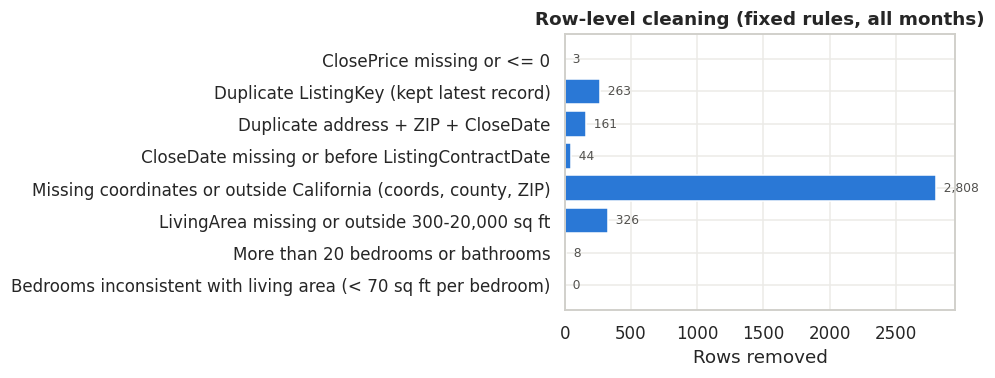

In [6]:
fig, ax = plt.subplots(figsize=(9, 3.6))
r = removal_log.iloc[1:].iloc[::-1]
ax.barh(r.step, r.removed, color=BLUE)
for i, v in enumerate(r.removed): ax.text(v, i, f"  {v:,}", va="center", fontsize=8, color="#52514e")
ax.set_xlabel("Rows removed"); ax.set_title("Row-level cleaning (fixed rules, all months)")
plt.tight_layout(); save(fig, "cleaning_log"); plt.show()

## 5. Per-row features (no information from other rows)

- `log_price = log(ClosePrice)`: the modelling target. Week 2 showed `ClosePrice` is extremely right-skewed (skewness about 132) and close to normal on a log scale.
- `log_living_area`, `log_lot_sqft`: both are heavy-tailed; logs make them usable by a linear model.
- `age` = valuation year − `YearBuilt` (property age at the time of prediction, not just build year).
- `month_sin`, `month_cos`: valuation month on a circle, so December sits next to January (Week 2 found a spring/summer lift of about 10%).
- `hoa_monthly`: `AssociationFee` converted to a monthly amount using `AssociationFeeFrequency` (blank frequency treated as monthly).
- `levels_cat`: `Levels` collapsed to One / Two / ThreeOrMore / MultiSplit, falling back to `Stories` when blank.
- Yes/No flags converted to 1 / 0 / missing. `HighSchoolDistrict` = "Other" is recoded as missing.

In [7]:
clean = pp.add_row_features(clean)
clean[["ClosePrice", "log_price", "LivingArea", "log_living_area", "LotSizeSquareFeet", "log_lot_sqft",
       "age", "hoa_monthly", "month_sin", "month_cos"]].describe().T

,count,mean,std,min,25%,50%,75%,max
ClosePrice,"306,122.000","1,288,376.370","5,616,234.081",1.150,"623,000.000","890,000.000","1,425,000.000","989,500,000.000"
log_price,"306,122.000",13.779,0.672,0.140,13.342,13.699,14.170,20.713
LivingArea,"306,122.000","2,033.299","1,018.625",300.000,"1,377.000","1,804.000","2,421.000","20,000.000"
log_living_area,"306,122.000",7.521,0.428,5.704,7.228,7.498,7.792,9.903
LotSizeSquareFeet,"300,360.000","23,021.307","231,641.652",100.000,"5,663.000","7,253.000","10,348.000","41,861,160.000"
log_lot_sqft,"300,360.000",9.074,0.871,4.605,8.642,8.889,9.245,17.550
age,"305,938.000",49.037,27.447,0.000,27.000,49.000,69.000,172.000
hoa_monthly,"215,070.000",77.532,163.224,0.000,0.000,0.000,110.000,"5,000.000"
month_sin,"306,122.000",0.082,0.723,-1.000,-0.500,0.000,0.866,1.000
month_cos,"306,122.000",-0.048,0.684,-1.000,-0.500,-0.000,0.500,1.000


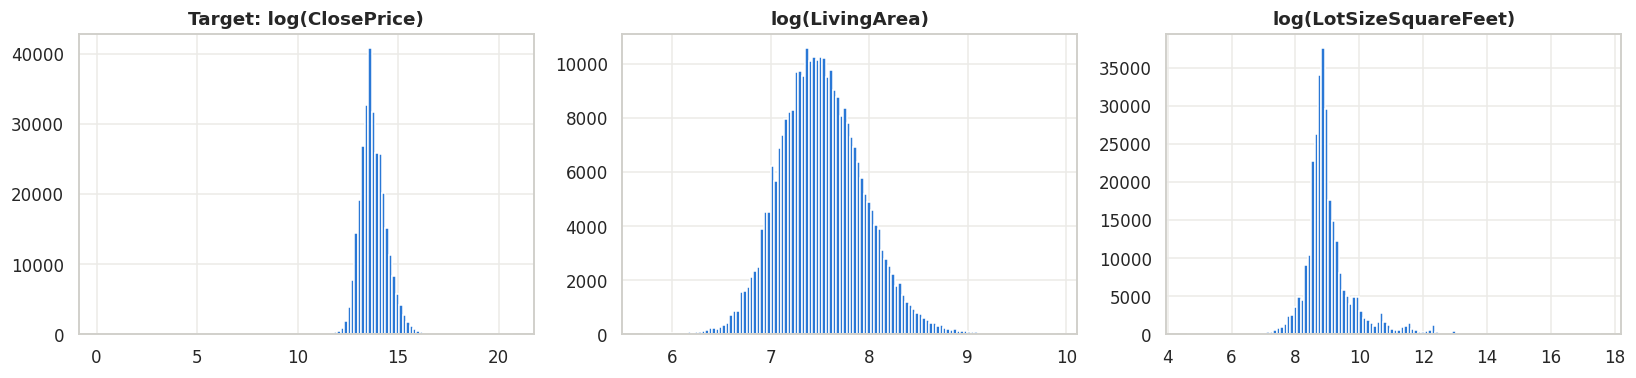

Skewness  ClosePrice: 134.6  ->  log_price: 0.46


In [8]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
ax[0].hist(clean.log_price, bins=120, color=BLUE); ax[0].set_title("Target: log(ClosePrice)")
ax[1].hist(clean.log_living_area, bins=120, color=BLUE); ax[1].set_title("log(LivingArea)")
ax[2].hist(clean.log_lot_sqft.dropna(), bins=120, color=BLUE); ax[2].set_title("log(LotSizeSquareFeet)")
plt.tight_layout(); save(fig, "log_transforms"); plt.show()
print(f"Skewness  ClosePrice: {clean.ClosePrice.skew():.1f}  ->  log_price: {clean.log_price.skew():.2f}")

## 6. Comp-based neighborhood prices (time-safe)

Location dominates price (Week 2: a six-fold spread in county medians). The team rule says price per square foot must not come from a row's own `ClosePrice`; instead it should come from **nearby sales**. For every sale closing in month *m*:

1. Comp pool = cleaned sales that closed in the 12 months **strictly before** *m* (never the same month, never later), with a sane price per sq ft ($50–$3,000, fixed domain bounds).
2. Find the 10 nearest comps by great-circle distance (`BallTree`, haversine).
3. Record `comp_log_ppsf` (log median comp price per sq ft), `comp_log_price` (median comp log price) and `comp_log_dist_km` (log median comp distance, a reliability signal: rural homes have far-away comps).

This is the same calculation that would run for an off-market address valued today, and it never sees the row's own price or any later sale. That makes it leakage-free for **any** split, so it is computed once here. Sales in January 2024 (the first month of data) have no earlier comps; those values are missing and imputed with an indicator.

In [9]:
clean = pp.add_comp_features(clean, k=10, lookback_months=12)
cov = clean.groupby("close_month").agg(rows=("log_price", "size"), comp_coverage=("comp_log_ppsf", lambda s: s.notna().mean()),
                                       pool_months=("comp_pool_months", "max"))
print(cov.T.to_string())
print("\nRank correlation with log_price:")
print(clean[["log_price", "comp_log_price", "comp_log_ppsf", "log_living_area", "comp_log_dist_km"]]
      .corr(method="spearman")["log_price"].drop("log_price").round(3).to_string())

close_month     2024-01   2024-02    2024-03    2024-04    2024-05    2024-06    2024-07    2024-08    2024-09    2024-10    2024-11    2024-12   2025-01   2025-02    2025-03    2025-04    2025-05    2025-06    2025-07    2025-08    2025-09    2025-10   2025-11    2025-12   2026-01   2026-02    2026-03    2026-04
rows          8,300.000 7,134.000 11,603.000 12,693.000 13,774.000 12,505.000 13,329.000 12,370.000 10,870.000 12,317.000 10,649.000 10,586.000 8,115.000 8,826.000 10,579.000 11,844.000 11,721.000 11,664.000 12,088.000 11,412.000 11,424.000 11,997.000 9,698.000 10,427.000 7,460.000 8,880.000 11,475.000 12,382.000
comp_coverage     0.000     1.000      1.000      1.000      1.000      1.000      1.000      1.000      1.000      1.000      1.000      1.000     1.000     1.000      1.000      1.000      1.000      1.000      1.000      1.000      1.000      1.000     1.000      1.000     1.000     1.000      1.000      1.000
pool_months         NaN     1.000      2.000      3.000

comp_log_price     0.922
comp_log_ppsf      0.798
log_living_area    0.508
comp_log_dist_km   0.006


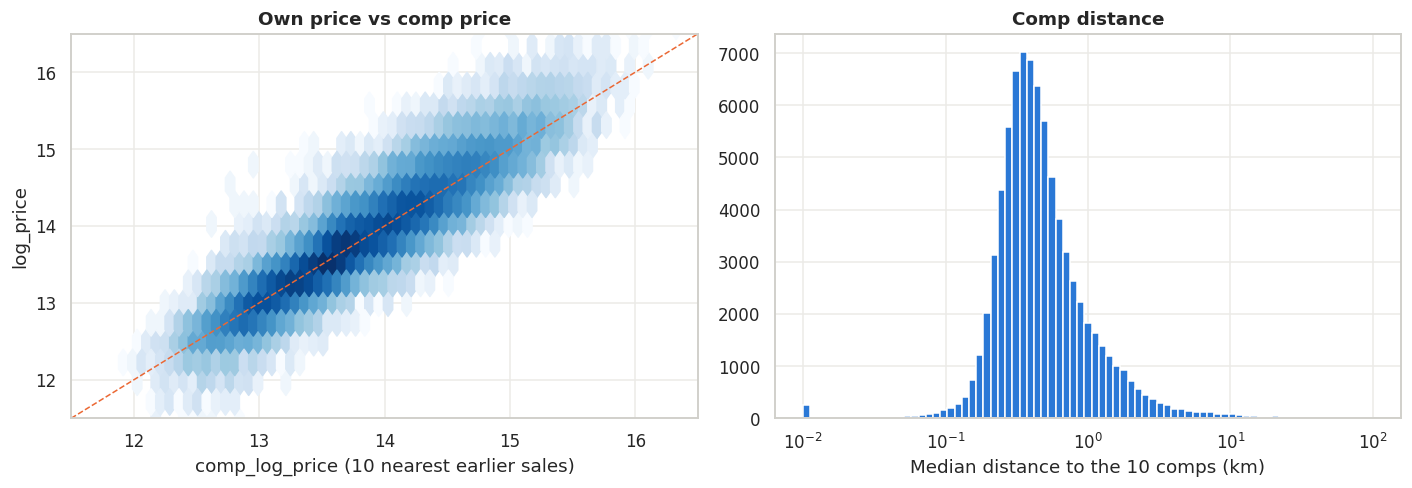

In [10]:
s = clean.dropna(subset=["comp_log_price"]).sample(80000, random_state=pp.SEED)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
ax[0].hexbin(s.comp_log_price, s.log_price, gridsize=70, cmap="Blues", mincnt=3, bins="log")
lims = [11.5, 16.5]; ax[0].plot(lims, lims, color=ORANGE, lw=1, ls="--"); ax[0].set_xlim(lims); ax[0].set_ylim(lims)
ax[0].set_xlabel("comp_log_price (10 nearest earlier sales)"); ax[0].set_ylabel("log_price"); ax[0].set_title("Own price vs comp price")
ax[1].hist(np.exp(s.comp_log_dist_km), bins=np.logspace(-2, 2, 80), color=BLUE); ax[1].set_xscale("log")
ax[1].set_xlabel("Median distance to the 10 comps (km)"); ax[1].set_title("Comp distance")
plt.tight_layout(); save(fig, "comp_features"); plt.show()

## 7. Missing values, encoding and scaling: one pipeline, fit on train only

Every learned step lives in `pp.build_preprocessor()`, a scikit-learn `ColumnTransformer`. Calling `fit` on the training window and `transform` on the test month makes leakage structurally impossible.

| Group | Columns | Missing values | Encoding / scaling |
|---|---|---|---|
| Numeric (15) | log living area, beds, baths, log lot, age, garage, parking, HOA, lat/lon, 3 comp features, month sin/cos | Median of the **training** window, plus a 0/1 missing-indicator column for every column that has gaps | Standardized (mean 0, sd 1) |
| Binary (4) | Pool, View, Fireplace, Attached garage | Filled with 0 plus a missing indicator (missing is not the same as "No") | Already 0/1 |
| Low-cardinality (2) | County (58), levels category | "Unknown" category | One-hot; categories with fewer than 30 training rows pooled as "infrequent" |
| High-cardinality (3) | ZIP (about 1,500), City (about 1,000), High-school district (about 440) | "Unknown" category | **Cross-fitted target encoding** of log price (each training row's code is computed from the other 4 folds, so it never sees its own label), then standardized |

Why these choices:
- **Impute, do not drop.** The model must value any address, including ones with gaps in their records, so it has to handle missing inputs. The indicators let it learn if missingness itself carries meaning (for example, a blank HOA fee usually means no HOA).
- **Target encoding instead of one-hot for ZIP and City** keeps the feature count small (one-hot would add about 2,500 sparse columns) and is the approach the best-practices guide recommends. Cross-fitting is what keeps it leak-free.
- **Scaling** matters for the linear baseline (Week 4) and is harmless for tree models.

The missing-value rates below are on the final training window chosen in section 9.

In [11]:
strategy = {**{c: "median + indicator" for c in pp.NUM_FEATURES}, **{c: "0 + indicator" for c in pp.BIN_FEATURES},
            **{c: "'Unknown' -> one-hot" for c in pp.LOWCARD_FEATURES}, **{c: "'Unknown' -> target encoding" for c in pp.HIGHCARD_FEATURES}}
miss_tbl = pd.DataFrame({"pct_missing_all_months": clean[pp.FEATURES].isna().mean() * 100,
                         "n_unique": clean[pp.FEATURES].nunique(), "handling": pd.Series(strategy)})
miss_tbl.sort_values("pct_missing_all_months", ascending=False)

,pct_missing_all_months,n_unique,handling
HighSchoolDistrict,33.127,442,'Unknown' -> target encoding
hoa_monthly,29.744,3157,median + indicator
AttachedGarageYN,11.588,2,0 + indicator
PoolPrivateYN,9.391,2,0 + indicator
levels_cat,9.139,4,'Unknown' -> one-hot
ViewYN,8.724,2,0 + indicator
GarageSpaces,3.707,27,median + indicator
comp_log_price,2.711,78630,median + indicator
comp_log_dist_km,2.711,295730,median + indicator
comp_log_ppsf,2.711,203253,median + indicator


## 8. Train-only outlier thresholds

Per best-practices section 03, the 0.5th and 99.5th percentiles of `ClosePrice` are computed on the **training window only** and the same frozen cutoffs are applied to the test month. A secondary 0.5th / 99.5th percentile filter on price per square foot (also train-only) catches data-entry errors a price filter misses (for example a \$6M "sale" of a 900 sq ft house). Price per sq ft is used here only to *filter rows*; it is never a feature.

`pp.fit_thresholds(train)` and `pp.within_thresholds(df, thresholds)` implement this; they run inside every split below, so each training window gets its own thresholds.

## 9. Choosing the training window X

**Split rule (game plan):** test = the most recent month (**April 2026**); train = the X months immediately before it. X is a tuning choice, so it is chosen **without touching April 2026**: per best-practices section 01, the test month is used only once, at the end.

**Experiment (rolling-origin validation).** For each validation month *v* in **January, February and March 2026** and each X in {1, 2, 3, 4, 6, 9, 12, 15, 18, 24}:
1. train = the X months before *v*; learn price thresholds on train; filter train and *v* with them;
2. fit the full preprocessing pipeline on train only;
3. fit two fixed models on log price: **Linear Regression** (the Week 4 baseline family) and **HistGradientBoosting** (a tree model with fixed, untuned settings);
4. score *v* in dollars: MdAPE (headline), MAPE, R², MAE.

Using three validation months instead of one guards against picking an X that is lucky for one month. 24 is the largest X that every validation month can support (January 2026 has 24 earlier months).

**The trade-off being tested.** Short windows reflect the current market but have fewer sales; long windows have more data but include older price levels. The comp features carry the recent price level, which should make longer windows less costly.

In [12]:
WINDOWS = [1, 2, 3, 4, 6, 9, 12, 15, 18, 24]
VAL_MONTHS = ["2026-01", "2026-02", "2026-03"]
TEST_MONTH = "2026-04"

def make_models():
    return {"LinearRegression": LinearRegression(),
            "HistGradientBoosting": HistGradientBoostingRegressor(
                max_iter=400, learning_rate=0.08, max_leaf_nodes=63, min_samples_leaf=40,
                l2_regularization=1.0, early_stopping=False, random_state=pp.SEED)}

rows = []
for v in VAL_MONTHS:
    for x in WINDOWS:
        tr, va = pp.window_split(clean, v, x)
        th = pp.fit_thresholds(tr)                       # learned on train only
        tr, va = tr[pp.within_thresholds(tr, th)], va[pp.within_thresholds(va, th)]
        for name, model in make_models().items():
            pipe = Pipeline([("prep", pp.build_preprocessor()), ("model", model)])
            pipe.fit(pp.model_frame(tr), tr[pp.TARGET])
            pred = np.exp(pipe.predict(pp.model_frame(va)))
            rows.append({"val_month": v, "X": x, "model": name, "n_train": len(tr), "n_val": len(va),
                         **pp.price_metrics(va.ClosePrice, pred)})
exp = pd.DataFrame(rows)
exp.to_csv(OUT_DIR / "train_window_experiment.csv", index=False)
summary = exp.groupby(["model", "X"])[["n_train", "MdAPE", "MAPE", "R2", "MAE", "within_10pct"]].mean()
summary["MdAPE_sd_across_months"] = exp.groupby(["model", "X"]).MdAPE.std()
summary

n_train  MdAPE   MAPE    R2         MAE  within_10pct  MdAPE_sd_across_months
model                X                                                                                   
HistGradientBoosting 1    8,790.000  8.488 12.012 0.888 155,503.621        56.550                   0.250
                     2   17,847.333  8.087 11.477 0.899 149,101.376        58.525                   0.182
                     3   28,394.667  7.844 11.217 0.906 145,305.878        59.583                   0.261
                     4   39,267.000  7.760 11.031 0.909 143,147.460        60.113                   0.246
                     6   62,165.000  7.654 10.858 0.912 140,894.959        60.725                   0.205
                     9   96,909.000  7.504 10.835 0.916 138,934.951        61.219                   0.182
                     12 127,414.000  7.485 10.786 0.918 137,158.729        61.537                   0.197
                     15 157,088.333  7.408 10.754 0.919 136,159.806        61.898                   0.247
                     18 191,863.333  7.328 10.708 0.919 135,884.827        62.225                   0.205
                     24 261,829.000  7.402 10.715 0.919 135,460.766        61.866                   0.217
LinearRegression     1    8,790.000  8.830 12.209 0.880 157,771.823        55.024                   0.272
                     2   17,847.333  8.800 12.221 0.879 157,810.836        55.236                   0.220
                     3   28,394.667  8.784 12.261 0.879 157,732.853        55.273                   0.170
                     4   39,267.000  8.818 12.204 0.880 157,843.278        55.271                   0.234
                     6   62,165.000  8.783 12.123 0.880 157,885.456        55.262                   0.227
                     9   96,909.000  8.768 12.177 0.881 157,311.484        55.418                   0.173
                     12 127,414.000  8.730 12.227 0.882 156,952.396        55.452                   0.201
                     15 157,088.333  8.747 12.245 0.882 156,588.212        55.438                   0.202
                     18 191,863.333  8.742 12.203 0.881 156,673.986        55.478                   0.186
                     24 261,829.000  8.929 12.504 0.878 159,192.527        54.588                   0.350

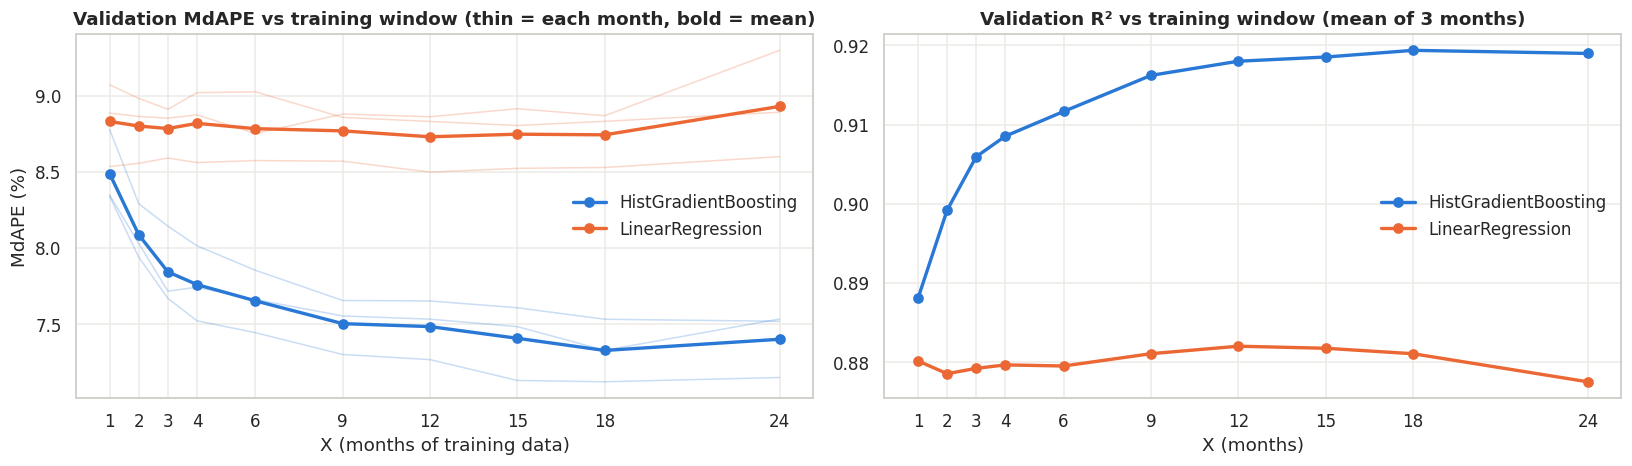

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.4))
for name, col in [("HistGradientBoosting", BLUE), ("LinearRegression", ORANGE)]:
    e = exp[exp.model == name]
    for v in VAL_MONTHS:
        f = e[e.val_month == v]; ax[0].plot(f.X, f.MdAPE, color=col, alpha=0.25, lw=1)
    m = e.groupby("X").MdAPE.mean(); ax[0].plot(m.index, m.values, color=col, lw=2.2, marker="o", label=name)
    m2 = e.groupby("X").R2.mean(); ax[1].plot(m2.index, m2.values, color=col, lw=2.2, marker="o", label=name)
ax[0].set_title("Validation MdAPE vs training window (thin = each month, bold = mean)")
ax[0].set_xlabel("X (months of training data)"); ax[0].set_ylabel("MdAPE (%)"); ax[0].legend(frameon=False)
ax[1].set_title("Validation R² vs training window (mean of 3 months)"); ax[1].set_xlabel("X (months)"); ax[1].legend(frameon=False)
for a in ax: a.set_xticks(WINDOWS)
plt.tight_layout(); save(fig, "train_window_experiment"); plt.show()

**Selection rule (fixed before looking at the results):** use the HistGradientBoosting curve, because the later models (Random Forest, gradient boosting) are tree models, and pick the **smallest X whose mean validation MdAPE is within 0.10 percentage points of the best X**. A smaller window is preferred when the accuracy is effectively tied, because it reflects the current market and retrains faster. Later weeks can re-run this experiment for their own models with the same code.

In [14]:
hgb = summary.loc["HistGradientBoosting"]
best_mdape = hgb.MdAPE.min()
X_BEST = int(hgb.index[hgb.MdAPE <= best_mdape + 0.10].min())
lr = summary.loc["LinearRegression"]
print(f"HistGradientBoosting: best mean MdAPE {best_mdape:.2f}% at X = {int(hgb.MdAPE.idxmin())}; "
      f"chosen X = {X_BEST} (MdAPE {hgb.loc[X_BEST, 'MdAPE']:.2f}%)")
print(f"LinearRegression:     best mean MdAPE {lr.MdAPE.min():.2f}% at X = {int(lr.MdAPE.idxmin())}; "
      f"at X = {X_BEST}: {lr.loc[X_BEST, 'MdAPE']:.2f}%")

HistGradientBoosting: best mean MdAPE 7.33% at X = 18; chosen X = 15 (MdAPE 7.41%)
LinearRegression:     best mean MdAPE 8.73% at X = 12; at X = 15: 8.75%


## 10. Final split, fit the preprocessing pipeline, and save the outputs

- **Test:** April 2026 (the most recent month). **Train:** the X months immediately before it.
- Price and price-per-sq-ft thresholds learned on train, frozen, applied to test.
- The preprocessing pipeline is fit on train only and saved (`processed/preprocessor.joblib`) so Week 4 onward and the app reuse the exact same imputation, encoding and scaling. The test month is **not scored** here; it stays untouched until the model weeks.

In [15]:
train, test = pp.window_split(clean, TEST_MONTH, X_BEST)
TH = pp.fit_thresholds(train)
keep_tr, keep_te = pp.within_thresholds(train, TH), pp.within_thresholds(test, TH)
print(f"Train window: {train.close_month.min()} to {train.close_month.max()} ({X_BEST} months) | Test: {TEST_MONTH}")
print("Thresholds learned on train:", {k: f"${v:,.0f}" for k, v in TH.items()})
print(f"Train: {len(train):,} rows -> {keep_tr.sum():,} after thresholds ({(~keep_tr).sum():,} removed, {(~keep_tr).mean():.2%})")
print(f"Test:  {len(test):,} rows -> {keep_te.sum():,} after thresholds ({(~keep_te).sum():,} removed, {(~keep_te).mean():.2%})")
train, test = train[keep_tr], test[keep_te]

Train window: 2025-01 to 2026-03 (15 months) | Test: 2026-04
Thresholds learned on train: {'price_lo': '$187,000', 'price_hi': '$8,500,000', 'ppsf_lo': '$144', 'ppsf_hi': '$2,300'}
Train: 157,610 rows -> 155,216 after thresholds (2,394 removed, 1.52%)
Test:  12,382 rows -> 12,175 after thresholds (207 removed, 1.67%)


In [16]:
prep = pp.build_preprocessor().fit(pp.model_frame(train), train[pp.TARGET])
Xtr = pd.DataFrame(prep.transform(pp.model_frame(train)), columns=prep.get_feature_names_out(), index=train.index)
Xte = pd.DataFrame(prep.transform(pp.model_frame(test)), columns=prep.get_feature_names_out(), index=test.index)
print(f"{len(pp.FEATURES)} input features -> {Xtr.shape[1]} model columns after imputation indicators, one-hot and encoding")
print("No missing values after preprocessing:", int(Xtr.isna().sum().sum()) == 0 and int(Xte.isna().sum().sum()) == 0)
scaled = [c for c in Xtr.columns if c.startswith(("num__", "high__")) and "missingindicator" not in c]
pd.DataFrame({"train_mean": Xtr[scaled].mean(), "train_sd": Xtr[scaled].std(),
              "test_mean": Xte[scaled].mean(), "test_sd": Xte[scaled].std()})

24 input features -> 82 model columns after imputation indicators, one-hot and encoding
No missing values after preprocessing: True


,train_mean,train_sd,test_mean,test_sd
num__log_living_area,-0.000,1.000,0.015,0.996
num__BedroomsTotal,0.000,1.000,-0.005,0.987
num__BathroomsTotalInteger,-0.000,1.000,0.014,1.006
num__log_lot_sqft,-0.000,1.000,0.003,1.014
num__age,-0.000,1.000,0.026,0.992
num__GarageSpaces,-0.000,1.000,-0.003,0.983
num__ParkingTotal,-0.000,1.000,0.012,1.013
num__hoa_monthly,0.000,1.000,0.046,1.129
num__Latitude,-0.000,1.000,0.004,1.007
num__Longitude,0.000,1.000,-0.008,1.005


Train means are 0 and standard deviations 1 by construction. Test means sit close to 0 but not exactly, because the test month is transformed with the **training** medians, encodings and scaling, as it should be.

In [17]:
# ---- cleaned CSV: every cleaned month, with the final split marked ----
clean["split"] = "outside_window"
clean.loc[train.index, "split"] = "train"; clean.loc[test.index, "split"] = "test"
in_window = clean.close_month.between(pd.Period(TEST_MONTH) - X_BEST, pd.Period(TEST_MONTH))
clean.loc[in_window & (clean.split == "outside_window"), "split"] = "removed_by_train_thresholds"

OUT_COLS = ["ListingKey", "UnparsedAddress", "City", "zip5", "CountyOrParish", "Latitude", "Longitude",
            "HighSchoolDistrict", "CloseDate", "close_month", "ClosePrice", "log_price",
            "LivingArea", "BedroomsTotal", "BathroomsTotalInteger", "LotSizeSquareFeet", "YearBuilt",
            "GarageSpaces", "ParkingTotal", "hoa_monthly", "PoolPrivateYN", "ViewYN", "FireplaceYN",
            "AttachedGarageYN", "levels_cat", "log_living_area", "log_lot_sqft", "age", "month_sin", "month_cos",
            "comp_log_ppsf", "comp_log_price", "comp_log_dist_km", "comp_pool_months", "split"]
assert not set(OUT_COLS) & set(pp.LEAKAGE_FIELDS), "banned field in output"
clean[OUT_COLS].to_csv(OUT_DIR / "sold_sfr_clean.csv", index=False)

model_cols = ["ListingKey", "close_month"] + pp.FEATURES + ["ClosePrice", pp.TARGET]
train[model_cols].to_csv(OUT_DIR / "train.csv", index=False)
test[model_cols].to_csv(OUT_DIR / "test.csv", index=False)
joblib.dump(prep, OUT_DIR / "preprocessor.joblib")

config = {
    "test_month": TEST_MONTH, "train_window_months": X_BEST,
    "train_months": [str(train.close_month.min()), str(train.close_month.max())],
    "thresholds_learned_on_train": TH, "target": "log(ClosePrice)",
    "features": {"numeric": pp.NUM_FEATURES, "binary": pp.BIN_FEATURES,
                 "low_cardinality": pp.LOWCARD_FEATURES, "high_cardinality": pp.HIGHCARD_FEATURES},
    "excluded_fields": pp.LEAKAGE_FIELDS,
    "comp_features": {"k": 10, "lookback_months": 12, "rule": "strictly earlier months only"},
    "rows": {"single_family_loaded": len(raw), "after_row_cleaning": len(clean), "train": len(train), "test": len(test)},
    "seed": pp.SEED, "data_snapshot": inventory.file.tolist(),
    "versions": {"python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__,
                 "scikit-learn": sklearn.__version__},
}
(OUT_DIR / "preprocessing_config.json").write_text(json.dumps(config, indent=2))
print(clean.split.value_counts().to_string())
for f in sorted(OUT_DIR.iterdir()): print(f"{f.name:32s} {f.stat().st_size/1e6:8.1f} MB")

split
train                          155216
outside_window                 136130
test                            12175
removed_by_train_thresholds      2601
preprocessing_config.json             0.0 MB
preprocessor.joblib                   0.1 MB
sold_sfr_clean.csv                  106.1 MB
test.csv                              3.5 MB
train.csv                            43.8 MB
train_window_experiment.csv           0.0 MB


## 11. Summary and hand-off to Week 4

**Cleaning.** 309,735 single-family sales (January 2024 – April 2026) became **306,122 after the row-level rules (1.17% removed)**. The largest step is missing or out-of-California coordinates (2,808 rows). Most of those are in the February 2024 file, which has no back-filled coordinates; that month is outside the final training window. 1,082 implausible values (0 beds/baths, impossible lot sizes, garage/parking/HOA typos) were set to missing and are imputed, not deleted.

**Features (24 inputs, 82 model columns).** All 24 are available for any address at prediction time: size, beds, baths, lot, age, garage/parking, HOA, pool/view/fireplace/attached garage, levels, latitude/longitude, county, ZIP, city, high-school district, valuation-month seasonality, and three **comp-based neighborhood price features** built only from earlier sales. The comp price has a 0.92 rank correlation with the sale's own log price, the strongest legitimate signal in the data. No list-price, days-on-market or contract-date field, and nothing derived from them, is an input or in any output file.

**Missing values, encoding, scaling.** Columns over 35% missing were dropped. The rest are imputed (median or 0, always with missing-indicator columns), county and levels are one-hot encoded, ZIP / city / school district are cross-fitted target encoded, and numeric columns are standardized. All of it is inside one `ColumnTransformer` fit on the training window only (`processed/preprocessor.joblib`).

**Training window X = 15 months.** Rolling-origin validation on January, February and March 2026 (the test month was not used):
- HistGradientBoosting improves steadily from X = 1 (MdAPE 8.49%) to about X = 12, then flattens: 7.49% at 12, **7.41% at 15**, 7.33% at 18 (best), 7.40% at 24. The selection rule (smallest X within 0.10 points of the best) picks **15**.
- Linear Regression is almost flat (MdAPE 8.73–8.83% for X = 1 to 18) and gets worse at X = 24 (8.93%). A linear model cannot adjust for older price levels, so very long windows hurt it.
- The result is robust in a practical sense: any X from 12 to 18 is within 0.16 points. Fewer than 6 months clearly costs accuracy.

**Final split.** Train = **January 2025 – March 2026** (157,610 rows); test = **April 2026** (12,382 rows). Thresholds learned on train only: ClosePrice **$187,000 – $8,500,000**, price per sq ft **$144 – $2,300**. After applying the same frozen thresholds to both, train has **155,216** rows (1.52% removed) and test has **12,175** (1.67% removed).

**Honest-metrics note.** The validation MdAPE of about 7.4% (R² about 0.92) comes from a model that never sees a listing-only field. It is the honest number, and it was used only to choose X. The April 2026 test month has not been scored and stays untouched until the model weeks.

**Outputs (`processed/`).**
- `sold_sfr_clean.csv`: every cleaned month with all model-safe columns, engineered features and a `split` column (train / test / outside_window / removed_by_train_thresholds).
- `train.csv`, `test.csv`: model-ready rows (24 features + `ClosePrice` + `log_price`), unscaled; scaling happens inside the saved pipeline.
- `preprocessor.joblib`: the fitted imputation, encoding and scaling pipeline.
- `preprocessing_config.json`: X, thresholds, feature lists, excluded fields, seed, file snapshot and package versions.
- `train_window_experiment.csv`: every validation run.

**Hand-off to Week 4 (baseline).** Load `train.csv` / `test.csv`, wrap `preprocessor.joblib` (or `pp.build_preprocessor()`) and `LinearRegression` in one `Pipeline`, fit on log price, and report R², MAPE, MdAPE and MAE on April 2026. Known limitations: high-school district is unknown for 33% of rows (the Week 6 school-district spatial join will replace it); comp features are not time-adjusted within their 12-month lookback; the seasonality columns are constant within a single test month, as expected.